# Frequency-search results explorer

Look at the output of an adversarial frequency search (`freq_search.py`): the
per-`(letter, pattern)` multipliers, the resulting per-word frequencies, and the
greedy strategy analyzed the *same way* as in `strategy_explorer` but under the
adversarial weighting (greedy playing against the adversarial word choices).

Generate a run first with e.g. `python math/freq_search.py 5` (saves to
`math/data/freq_search/len05.csv`); this notebook loads it back.

In [1]:
from pathlib import Path
import sys

def find_math_dir():
    cwd = Path.cwd().resolve()
    for c in (cwd, cwd.parent, cwd.parent.parent, cwd / 'math', cwd.parent / 'math'):
        if (c / 'freq_search.py').exists():
            return c
    raise FileNotFoundError('Could not find freq_search.py. Open from the repo root, math/, or math/notebooks/.')

math_dir = find_math_dir()
if str(math_dir) not in sys.path:
    sys.path.insert(0, str(math_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import freq_search, strategy

print(f'imported from {math_dir}')

imported from /Users/patrickliscio/My Documents/Pycharm Projects/Ballpark-Figures/hangman/math


## Load a search result

Loads the saved CSV for this length if present; otherwise runs one inline (which
can be slow for larger lengths).

In [62]:
LENGTH = 10
OBJECTIVE = 'greedy'      # 'greedy' or 'best_opener' -- which tuned run to explore below

csv_path = freq_search._default_log_path(OBJECTIVE, LENGTH)
if csv_path.exists():
    s = freq_search.FrequencySearch.reconstruct(LENGTH, csv_path, objective=OBJECTIVE)
    print(f'loaded {OBJECTIVE} run: {csv_path.parent.name}/{csv_path.name}')
else:
    print(f'no saved run at {csv_path}\nrunning one inline (may take a while)...')
    s = freq_search.FrequencySearch(LENGTH, objective=OBJECTIVE)
    s.run(verbose=False)

game, f = s.game, s.freq
bo_letter, bo = game.best_opener_misses(f)
print(f'length {LENGTH} [{OBJECTIVE}]: {game.N} words, {s.M} patterns')
print(f'on this tuned distribution -- pure greedy {game.average_misses(f):.4f}   '
      f'best opener {bo:.4f} (via {bo_letter!r})')

loaded greedy run: freq_search/len10.csv
length 10 [greedy]: 3359 words, 1089 patterns
on this tuned distribution -- pure greedy 1.2146   best opener 0.8857 (via 'e')


## Compare objectives: greedy-tuned vs best-opener-tuned

Load **both** adversarial runs for this length (if present) and score each tuned
distribution with **both** guessers: `greedy_avg` = pure greedy, `best_opener_avg`
= the guesser who picks the best first letter then plays greedy. A distribution
tuned only against *pure greedy* can be escaped by a smarter opener (large `gap`);
one tuned against the *best-opener* guesser leaves little room to improve (small
`gap`). Missing runs are skipped — generate them with `python math/freq_search.py
<LEN>` and `... --best-opener`.

In [63]:
def load_run(objective):
    p = freq_search._default_log_path(objective, LENGTH)
    if not p.exists():
        print(f'  (no {objective!r} run for length {LENGTH} at {p.parent.name}/{p.name})')
        return None
    return freq_search.FrequencySearch.reconstruct(LENGTH, p, objective=objective)

# score each tuned distribution with BOTH guessers
rows = []
for objective in freq_search.OBJECTIVES:
    r = load_run(objective)
    if r is None:
        continue
    gm, fr = r.game, r.freq
    greedy = gm.average_misses(fr)
    bl, bv = gm.best_opener_misses(fr)
    rows.append({'tuned_for': objective,
                 'greedy_avg': greedy, 'greedy_opener': gm.greedy_first_letter(fr),
                 'best_opener_avg': bv, 'best_opener_letter': bl,
                 'gap': greedy - bv})
pd.DataFrame(rows).set_index('tuned_for').round(4)

,greedy_avg,greedy_opener,best_opener_avg,best_opener_letter,gap
tuned_for,,,,,
greedy,1.2146,i,0.8857,e,0.3289
best_opener,1.1202,r,1.1202,s,0.0000


## Multipliers

One row per `(letter, pattern)`; `multiplier` is the tuned weight, `n_words` how
many words carry that pattern.

In [64]:
mult_df = s.multipliers_df()
print(f'{(mult_df.multiplier == 0).sum()} patterns of {len(mult_df)} zeroed; '
      f'{(mult_df.multiplier > 1).sum()} boosted above 1; '
      f'max multiplier {mult_df.multiplier.max():g}')
mult_df.head(50)

231 patterns of 1089 zeroed; 267 boosted above 1; max multiplier 47.375


,letter,pattern,mask,multiplier,n_words
0,e,_e_e_ee___,106,47.375,1
1,s,_s______ss,770,19.500,1
2,z,____zz____,48,16.375,1
3,u,_u_u__u_u_,330,16.375,1
4,d,___dd_____,24,16.000,1
5,t,_t_tt_____,26,15.000,1
6,o,o___o_o___,81,12.000,1
7,e,__e_e_e__e,596,9.375,2
8,g,_g________,2,9.250,1
9,e,e__e__e_e_,329,8.625,1


In [65]:
mult_df[mult_df['pattern'] == '____s']

,letter,pattern,mask,multiplier,n_words


In [66]:
mult_df.tail(50)

,letter,pattern,mask,multiplier,n_words
1039,p,___pp_____,24,0.0,1
1040,b,___bb_____,24,0.0,1
1041,t,__t___t_t_,324,0.0,1
1042,i,___i____i_,264,0.0,4
1043,t,______t_t_,320,0.0,1
1044,g,__g_____g_,260,0.0,2
1045,s,__s_____s_,260,0.0,1
1046,i,_i_i______,10,0.0,5
1047,k,___kk_____,24,0.0,1
1048,t,_t_t__t___,74,0.0,1


## Frequencies

One row per word (frequency = product of its pattern multipliers).

In [67]:
freq_df = s.frequencies_df()
print(f'{(freq_df.frequency == 0).sum()} words of {len(freq_df)} at frequency 0 (removed); '
      f'heaviest carry the adversarial weight:')
freq_df.head(50)

542 words of 3359 at frequency 0 (removed); heaviest carry the adversarial weight:


,word,frequency
0,acrobatics,32.00000
1,paragraphs,32.00000
2,myocardial,16.50000
3,commandant,16.00000
4,forthright,16.00000
5,autographs,16.00000
6,preemptive,16.00000
7,blacksmith,16.00000
8,schoolwork,16.00000
9,schoolboys,16.00000


In [68]:
freq_df.tail(50)

,word,frequency
3309,nomination,0.0
3310,nationwide,0.0
3311,assistants,0.0
3312,mistresses,0.0
3313,motorcycle,0.0
3314,irradiated,0.0
3315,disastrous,0.0
3316,diminished,0.0
3317,antithesis,0.0
3318,reconsider,0.0


## Uniform baseline + the two guessers on the tuned distribution

Each cell compares three lenses:

- **uniform** — every word equally likely (`freq=None`), pure greedy — the
  "normal game" baseline (the original `strategy_explorer` view);
- **pure greedy** — on the tuned distribution `f`, opens with its highest
  combined-frequency letter (`go`);
- **best opener** — on `f`, forces the single best first letter (`bo_letter`).

The greedy↔best-opener gap on `f` is exactly what the `best_opener` search targets.

uniform     : avg 0.6969  (opens 'e')
pure greedy : avg 1.2146  (opens 'i')
best opener : avg 0.8857  (opens 'e')


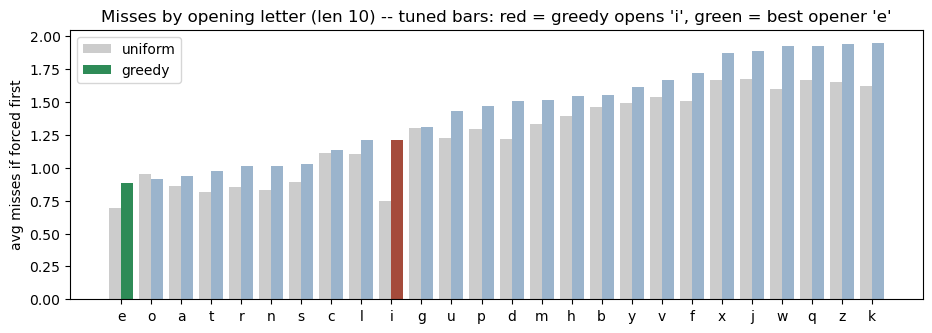

,e,o,a,t,r,n,s,c,l,i,...,b,y,v,f,x,j,w,q,z,k
uniform,0.696934,0.951176,0.86365,0.817208,0.852635,0.833581,0.890146,1.111640,1.105984,0.750223,...,1.465019,1.491218,1.535576,1.504019,1.665674,1.676689,1.597202,1.666270,1.655255,1.620125
greedy,0.885674,0.918195,0.93581,0.976857,1.010633,1.014459,1.026379,1.134287,1.209591,1.214603,...,1.549957,1.610432,1.667410,1.722844,1.873772,1.891268,1.922352,1.923641,1.937223,1.951341


In [69]:
# the three lenses: uniform baseline, then the two guessers on the tuned distribution
go = game.greedy_first_letter(f)                 # greedy's opener on f
print(f'uniform     : avg {game.average_misses(None):.4f}  (opens {game.greedy_first_letter(None)!r})')
print(f'pure greedy : avg {game.average_misses(f):.4f}  (opens {go!r})')
print(f'best opener : avg {bo:.4f}  (opens {bo_letter!r})')

# Mode B -- misses if each letter is forced first: uniform vs the tuned distribution;
# the tuned bars mark greedy's opener (red) and the best opener (green)
mbu = pd.Series(game.misses_by_starting_letter(None))
mba = pd.Series(game.misses_by_starting_letter(f))
order = list(mba.sort_values().index)
x = np.arange(len(order)); w = 0.4
adv_colors = ['#9bb4cc'] * len(order)
adv_colors[order.index(go)] = '#a54b3b'          # red = greedy opens here
adv_colors[order.index(bo_letter)] = '#2e8b57'   # green = best opener
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(x - w / 2, mbu[order].values, w, label='uniform', color='#cccccc')
ax.bar(x + w / 2, mba[order].values, w, label=OBJECTIVE, color=adv_colors)
ax.set_xticks(x); ax.set_xticklabels(order)
ax.set_ylabel('avg misses if forced first'); ax.legend()
ax.set_title(f'Misses by opening letter (len {LENGTH}) -- tuned bars: '
             f'red = greedy opens {go!r}, green = best opener {bo_letter!r}')
plt.show()
pd.DataFrame({'uniform': mbu[order], OBJECTIVE: mba[order]}).T

## Per-word difficulty: uniform vs greedy vs best opener

All three lenses, frequency-weighted (uniform weights each word equally; the two
tuned lenses weight by `f`; each normalized to a share of total weight).

weighted avg misses -- uniform 0.6969   pure greedy 1.2146   best opener 0.8857


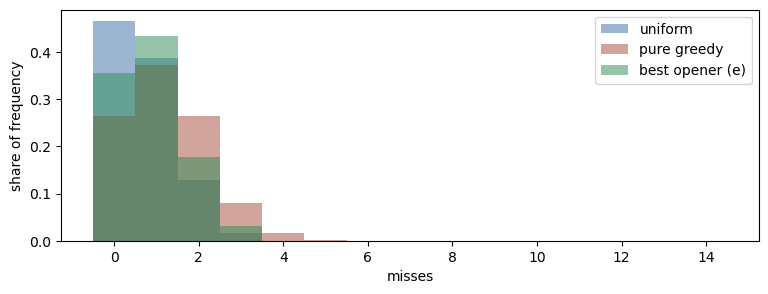

hardest words (pure greedy) under this distribution:


,word,freq,misses_uniform,misses_greedy,misses_best_opener
0,inventions,0.0,0,14,14
1,convention,0.0,0,14,14
2,contention,0.0,0,14,14
3,intentions,0.0,0,14,14
4,reparation,0.0,0,11,0
5,separation,0.0,0,11,0
6,narcissist,0.0,2,10,11
7,narcissism,0.0,1,9,10
8,enthusiast,0.0,0,9,9
9,repressive,0.0,1,8,6


In [70]:
upm = game.per_word_misses(None)                 # uniform baseline (pure greedy)
gpm = game.per_word_misses(f)                    # pure greedy on the tuned distribution
bpm = game.per_word_misses(f, opener=bo_letter)  # best opener on the tuned distribution
words = pd.DataFrame({'word': game.words, 'freq': f,
                      'misses_uniform':     upm.astype(int),
                      'misses_greedy':      gpm.astype(int),
                      'misses_best_opener': bpm.astype(int)})

print(f'weighted avg misses -- uniform {game.average_misses(None):.4f}   '
      f'pure greedy {game.average_misses(f):.4f}   best opener {bo:.4f}')

bins = range(0, int(max(upm.max(), gpm.max(), bpm.max())) + 2)
fig, ax = plt.subplots(figsize=(9, 3))
for pwm, wt, name, color in [(upm, None, 'uniform',                    '#3b6ea5'),
                             (gpm, f,    'pure greedy',                '#a54b3b'),
                             (bpm, f,    f'best opener ({bo_letter})', '#2e8b57')]:
    ax.hist(pwm, bins=bins, weights=wt, density=True,
            alpha=0.5, label=name, color=color, align='left')
ax.set_xlabel('misses'); ax.set_ylabel('share of frequency'); ax.legend()
plt.show()

print('hardest words (pure greedy) under this distribution:')
words.sort_values('misses_greedy', ascending=False).head(15).reset_index(drop=True)

In [71]:
# The adversary zeros out many words (freq 0) -- those don't count toward its
# average. Hardest words it actually KEEPS (nonzero frequency), with both guessers:
kept = words[words.freq > 0]
print(f'{len(kept)} of {len(words)} words kept (nonzero frequency)')
kept.sort_values('misses_greedy', ascending=False).head(15).reset_index(drop=True)

2817 of 3359 words kept (nonzero frequency)


,word,freq,misses_uniform,misses_greedy,misses_best_opener
0,homeopathy,1.00000,3,5,3
1,pocketbook,1.00000,1,5,0
2,hematology,1.00000,1,4,1
3,gobsmacked,0.50000,2,4,1
4,attracting,2.75000,1,4,3
5,passageway,0.50000,0,4,1
6,juxtaposed,0.03125,1,4,1
7,fluctuates,1.00000,2,4,1
8,psychopath,8.00000,2,4,1
9,hypotheses,1.00000,1,4,1


## Trace a word: uniform vs greedy vs best opener

The guess sequence for one word under each lens (`+` = hit, `-` = miss). On the
tuned distribution greedy opens with `go` and the best-opener guesser with
`bo_letter`; the uniform lens is the normal-game baseline.

In [72]:
# hardest word (pure greedy) the adversary actually KEEPS; or set WORD = 'bench'
nz = np.flatnonzero(f > 0)
WORD = game.words[nz[gpm[nz].argmax()]]
print(WORD)
for name, fr, kw in [('uniform', None, {}),
                     (f'greedy (opens {go})',      f, {}),
                     (f'best opener (opens {bo_letter})', f, {'opener': bo_letter})]:
    hits = game.trace(WORD, fr, **kw)
    seq = '  '.join(f'{l}{"+" if h else "-"}' for l, h in hits)
    print(f'{name:>26}  ({sum(1 for _, h in hits if not h)} misses):  {seq}')

homeopathy
                   uniform  (3 misses):  e+  n-  r-  i-  a+  h+  m+  o+  p+  t+  y+
          greedy (opens i)  (5 misses):  i-  r-  n-  l-  s-  e+  a+  h+  m+  o+  p+  t+  y+
     best opener (opens e)  (3 misses):  e+  i-  r-  n-  a+  h+  m+  o+  p+  t+  y+
